# ****PREPROCESSING AND EXPLORATORY DATA ANALYSIS****

Notebook ini membersihkan data harga, menetapkan pembagian data latih, validasi, dan uji, serta menyelidiki pola harga sebagai dasar perancangan model.

<p align="center">
    <img src="../xLain_Lain/img/peda_0.png" alt="Preprocessing and Exploratory Data Analysis" witdh="100" height="500">
</p>

---

### ****DAFTAR ISI****

0. Persiapan Lingkungan Kerja dan Pemuatan Data
1. Penanganan Data Kosong
2. Pemeriksaan Nilai Tidak Wajar
3. Penyimpanan Data Bersih
4. Pembagian Data Latih, Validasi, dan Uji
5. Eksplorasi Pola Harga
6. Implikasi bagi Pemodelan
7. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan Lingkungan Kerja dan Pemuatan Data****

#### ****0.1 Mengapa langkah ini penting?****

Notebook ini selalu mulai dari berkas mentah yang sama dan memuatnya dengan fungsi pemuat yang sama seperti pada notebook sebelumnya. Dengan cara ini seluruh langkah pembersihan tercatat dan dapat diulang dari awal, bukan hasil suntingan manual pada berkas.

#### ****0.2 Memuat data****

Sel berikut memuat paket, memuat data harga, lalu mencatat jumlah hari tercatat, hari kosong, dan data valid.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from src.data_utils import muat_pihps_lebar

harga = muat_pihps_lebar(config.FILE_RAW, config.KOMODITAS)
rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

print(f"Data dimuat : {len(harga)} hari kerja ({harga.index.min().date()} sampai {harga.index.max().date()})")
print(f"Data kosong : {int(harga.isna().sum())}")
print(f"Data valid : {int(harga.notna().sum())}")

Data dimuat : 1790 hari kerja (2020-01-01 sampai 2026-11-10)
Data kosong : 44
Data valid : 1746


>INTERPRETASI (Pemuatan data)
>
>Data termuat sesuai temuan Notebook 2: 1.790 hari kerja dari 1 Januari 2020 sampai 10 November 2026, terdiri atas 44 hari kosong dan 1.746 data valid. Angka yang sama dengan sebelumnya menunjukkan fungsi pemuat data bekerja konsisten.

### ****1. Penanganan Data Kosong****

#### ****1.1 Mengapa langkah ini penting?****

Pada Notebook 2 ditemukan 44 hari kosong (2,5%) yang seluruhnya berada pada 2020 sampai 2022. Cara menanganinya memengaruhi hubungan antara satu hari dan hari berikutnya, padahal hubungan itulah bahan utama Fuzzy Time Series. Pengisian yang sembarangan dapat menciptakan pola yang tidak pernah terjadi.

#### ****1.2 Tiga pilihan penanganan****

1. A. Hapus hari kosong. Tidak ada nilai buatan, tetapi dua pencatatan yang dipisahkan hari kosong menjadi bertetangga.
2. B. Isi dengan harga hari sebelumnya. Jumlah data utuh, tetapi harga seolah tidak berubah selama hari kosong.
3. C. Interpolasi linear. Deret tampak mulus, tetapi nilai yang diisikan tidak pernah tercatat dan lonjakan asli menjadi lebih lembut.

Keputusan ditetapkan setelah melihat bukti dari data.

#### ****1.3 Yang diperiksa****

Dua sel berikut memeriksa:
1. Perbandingan ketiga cara: jumlah data, simpangan baku perubahan harian, rata-rata perubahan mutlak, jumlah perubahan tepat nol, dan perubahan terbesar.
2. Perbandingan perubahan harga antara dua pencatatan berurutan yang tidak dipisahkan hari kosong dengan yang dipisahkan hari kosong.

In [2]:
valid = harga.dropna()

strategi = {
    "A. Hapus hari kosong": valid,
    "B. Isi dengan harga hari sebelumnya": harga.ffill().dropna(),
    "C. Interpolasi linear": harga.interpolate(method="time", limit_area="inside").dropna(),
}

baris = []
for nama, s in strategi.items():
    p = s.pct_change().dropna() * 100
    baris.append({
        "strategi": nama,
        "jumlah_data": len(s),
        "std_perubahan_%": p.std(),
        "rata2_mutlak_%": p.abs().mean(),
        "jumlah_perubahan_nol": int((p == 0).sum()),
        "perubahan_terbesar_%": p.abs().max(),
    })

print("=" * 62)
print("Perbandingan 3 cara menangani harga kosong tsb")
print("=" * 62)
print(pd.DataFrame(baris).set_index("strategi").round(2).T.to_string())

Perbandingan 3 cara menangani harga kosong tsb
strategi              A. Hapus hari kosong  B. Isi dengan harga hari sebelumnya  C. Interpolasi linear
jumlah_data                        1746.00                              1789.00                1789.00
std_perubahan_%                       6.44                                 6.36                   6.17
rata2_mutlak_%                        3.95                                 3.85                   3.85
jumlah_perubahan_nol                 91.00                               134.00                  91.00
perubahan_terbesar_%                 45.94                                45.94                  39.51


>INTERPRETASI (Perbandingan tiga cara menangani hari kosong)
>
>Ketiga cara menghasilkan gambaran volatilitas yang berbeda. Cara A (hapus) menyisakan 1.746 data dengan simpangan baku perubahan harian 6,44%, rata-rata perubahan mutlak 3,95%, dan 91 perubahan yang tepat nol. Cara B (isi dengan harga hari sebelumnya) menghasilkan 1.789 data (satu hari paling awal tidak dapat diisi karena tidak punya nilai sebelumnya) dengan 134 perubahan nol, atau 43 lebih banyak daripada cara A. Tambahan ini sama dengan jumlah hari kosong yang diisi dan merupakan perubahan nol buatan yang tidak pernah terjadi. Cara C (interpolasi linear) tidak menambah perubahan nol (tetap 91), tetapi menurunkan simpangan baku menjadi 6,17% dan perubahan terbesar dari 45,94% menjadi 39,51%, karena lonjakan nyata dibagi rata ke hari-hari yang sebenarnya tidak tercatat.
>
>Jadi cara B mengencerkan volatilitas dengan harga yang seolah diam, sedangkan cara C melunakkan lonjakan asli. Hanya cara A yang tidak mengubah perilaku data. Selisihnya memang kecil secara angka (simpangan baku 6,17% sampai 6,44%), tetapi arahnya konsisten dimana pengisian membuat data tampak lebih tenang daripada kenyataan.

In [3]:
sebelumnya = pd.Series(
    [len(pd.bdate_range(valid.index[i - 1], valid.index[i])) - 2 for i in range(1, len(valid))],
    index=valid.index[1:],
)
p = valid.pct_change().dropna() * 100
kelompok = np.where(sebelumnya > 0, "Melewati hari kosong", "Tanpa hari kosong di antaranya")

ringkas = p.groupby(kelompok).agg(
    jumlah="count",
    std="std",
    rata2_mutlak=lambda x: x.abs().mean(),
    terbesar=lambda x: x.abs().max(),
)

print("=" * 62)
print("Perubahan harga antar pencatatan berurutan (setelah hari kosong dihapus)")
print("=" * 62)
print(ringkas.round(2).to_string())
print()
print("Banyaknya hari kosong yang terlewati (hanya yang > 0):")
print(sebelumnya[sebelumnya > 0].value_counts().sort_index().to_string())

Perubahan harga antar pencatatan berurutan (setelah hari kosong dihapus)
                                jumlah    std  rata2_mutlak  terbesar
Melewati hari kosong                32  16.38         11.09     45.94
Tanpa hari kosong di antaranya    1713   6.10          3.81     39.51

Banyaknya hari kosong yang terlewati (hanya yang > 0):
1    27
2     2
3     2
6     1


>INTERPRETASI (Perubahan harga lintas hari kosong)
>
>Setelah hari kosong dihapus, ada 32 pasang pencatatan berurutan (1,8% dari 1.745 perubahan) yang sebenarnya dipisahkan satu hari kosong atau lebih: 27 pasang melewati satu hari kosong, 2 melewati dua hari, 2 melewati tiga hari, dan 1 melewati enam hari. Perubahan harga pada pasangan ini jauh lebih besar: simpangan baku 16,38% dibanding 6,10% pada pasangan tanpa hari kosong, dan rata-rata perubahan mutlak 11,09% dibanding 3,81%. Perubahan terbesar sepanjang data (45,94%) juga berada pada kelompok ini.
>
>Selisih ini wajar sebagian karena waktu yang berlalu lebih panjang, tetapi penyebab lain tidak diuji. Konsekuensinya, bila hari kosong dihapus, 32 lompatan ini akan masuk ke aturan Fuzzy Time Series pada data latih sebagai perpindahan antar himpunan fuzzy yang berjauhan. Jumlahnya kecil (1,8%) dan seluruhnya berada di data latih, sehingga dampaknya terbatas, tetapi tetap dicatat sebagai keterbatasan.

#### ****1.4 Keputusan****

Kami memilih cara A, yaitu menghapus hari kosong, dengan alasan:
1. Tidak ada nilai buatan. Cara B menambah 43 perubahan nol yang tidak pernah terjadi, dan cara C melunakkan lonjakan asli.
2. Seluruh hari kosong berada pada 2020 sampai 2022, sehingga data validasi dan uji tidak terpengaruh oleh pilihan apa pun.
3. Sejalan dengan tujuan sistem, yaitu meramalkan pencatatan harga berikutnya.

Konsekuensinya, 32 lompatan lintas hari kosong tetap berada pada data latih. Bila waktu memungkinkan, pengaruh pilihan ini dapat diuji sebagai uji sensitivitas di Notebook 6 dengan melatih ulang model pada data yang ditangani dengan cara B atau C.

### ****2. Pemeriksaan Nilai Tidak Wajar****

#### ****2.1 Mengapa langkah ini penting?****

Nilai ekstrem dapat berupa kejadian nyata atau kesalahan pencatatan. Membuang kejadian nyata merusak ciri asli data, sedangkan membiarkan kesalahan dapat menggeser batas semesta Fuzzy Time Series dan menyia-nyiakan satu interval pada rentang harga yang hampir tidak pernah muncul. Pada Notebook 1, harga terendah (21 Agustus 2020) tampak terpisah dari titik-titik di sekitarnya.

#### ****2.2 Cara membedakan****

Kami membedakan dua jenis:
1. Lonjakan berlanjut, yaitu harga naik atau turun lalu bertahan di tingkat baru. Ini dianggap kejadian nyata dan dipertahankan.
2. Anomali sesaat, yaitu satu titik yang menyimpang jauh dari kedua tetangganya padahal kedua tetangga itu saling berdekatan, sehingga harga seolah kembali seketika.

Aturan yang dipakai: sebuah titik disebut anomali sesaat bila deviasi logaritmiknya dari rata-rata dua tetangga melebihi 0,20 (setara sekitar 18% sampai 22%), dan selisih logaritmik antara kedua tetangga kurang dari 0,10. Kedua ambang ini adalah pertimbangan analis, bukan standar baku.

#### ****2.3 Yang dilakukan****

Tiga sel berikut:
1. Menampilkan titik dengan deviasi cukup besar beserta statusnya.
2. Menggambar sekitar titik yang terdeteksi sebagai anomali sesaat.
3. Merangkum jumlah data setelah pembersihan sejauh ini.

In [4]:
AMBANG_DEVIASI = 0.20
AMBANG_TETANGGA = 0.10

log_harga = np.log(valid)
deviasi = (log_harga - (log_harga.shift(1) + log_harga.shift(-1)) / 2).dropna()
jarak_tetangga = (log_harga.shift(-1) - log_harga.shift(1)).abs().reindex(deviasi.index)

kandidat = pd.DataFrame({
    "harga": valid.reindex(deviasi.index),
    "sebelum": valid.shift(1).reindex(deviasi.index),
    "sesudah": valid.shift(-1).reindex(deviasi.index),
    "deviasi_%": (np.exp(deviasi) - 1) * 100,
    "jarak_tetangga_%": (np.exp(jarak_tetangga) - 1) * 100,
})
kandidat["status"] = np.where(
    (deviasi.abs() > AMBANG_DEVIASI) & (jarak_tetangga < AMBANG_TETANGGA),
    "Anomali sesaat",
    "lonjakan berlanjut",
)

periksa = kandidat[deviasi.abs() > 0.15].sort_values("deviasi_%", key=abs, ascending=False)

print("=" * 62)
print("Pemeriksaan nilai tidak wajar")
print("=" * 62)
print(f"Aturan anomali sesaat: deviasi logaritmik > {AMBANG_DEVIASI} dari rata-rata dua tetangga,")
print(f"dan kedua tetangga saling berdekatan (selisih logaritmik < {AMBANG_TETANGGA}).")
print(f"Titik yang diperiksa: {len(kandidat)} (titik pertama dan terakhir tidak punya dua tetangga)")
print(f"Titik dengan deviasi logaritmik > 0.15: {len(periksa)}")
print()
print(periksa.round(1).to_string())

anomali = kandidat[kandidat["status"] == "Anomali sesaat"]
print()
print(f"Jumlah anomali sesaat terdeteksi: {len(anomali)}")

Pemeriksaan nilai tidak wajar
Aturan anomali sesaat: deviasi logaritmik > 0.2 dari rata-rata dua tetangga,
dan kedua tetangga saling berdekatan (selisih logaritmik < 0.1).
Titik yang diperiksa: 1744 (titik pertama dan terakhir tidak punya dua tetangga)
Titik dengan deviasi logaritmik > 0.15: 16

               harga  sebelum   sesudah  deviasi_%  jarak_tetangga_%              status
tanggal                                                                                 
2020-08-21   10250.0  15150.0   14300.0      -30.4               5.9      Anomali sesaat
2026-03-24   98700.0  98700.0   64050.0       24.1              54.1  lonjakan berlanjut
2020-08-19   15150.0  15300.0   10250.0       21.0              49.3  lonjakan berlanjut
2021-01-04   74500.0  51050.0   74950.0       20.4              46.8  lonjakan berlanjut
2021-04-19   43200.0  61950.0   46050.0      -19.1              34.5  lonjakan berlanjut
2020-08-24   14300.0  10250.0   14150.0       18.7              38.0  lonjakan b

>INTERPRETASI (Pemeriksaan nilai tidak wajar)
>
>Dari 1.744 titik yang punya dua tetangga, 16 titik memiliki deviasi logaritmik lebih dari 0,15, tetapi hanya satu yang memenuhi kedua aturan anomali sesaat: harga Rp 10.250 pada 21 Agustus 2020. Harga itu menyimpang 30,4% di bawah rata-rata kedua tetangganya (Rp 15.150 sebelumnya dan Rp 14.300 sesudahnya), padahal kedua tetangga itu hanya berselisih 5,9%.
>
>Lima belas titik lainnya tidak memenuhi aturan kedua karena kedua tetangganya berselisih jauh (13,6% sampai 64,1%), artinya harga bergeser ke tingkat baru dan bertahan di sana. Contohnya kenaikan dari Rp 51.050 ke Rp 74.500 pada 4 Januari 2021 yang berlanjut ke Rp 74.950, dan penurunan dari Rp 98.700 ke Rp 64.050 pada 25 Maret 2026 yang berlanjut ke Rp 60.150. Titik-titik ini dipertahankan karena merupakan perilaku asli harga cabai. Dua titik yang ikut tampil di daftar karena bersebelahan dengan anomali (19 Agustus dan 24 Agustus 2020) muncul semata-mata akibat nilai Rp 10.250 tersebut.

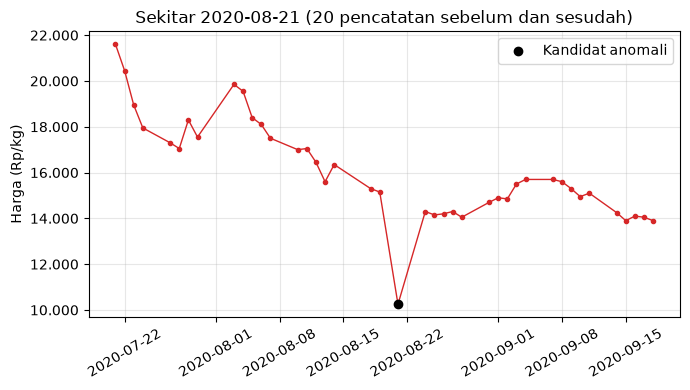

In [5]:
if len(anomali) > 0:
    fig, axes = plt.subplots(1, len(anomali), figsize=(7 * len(anomali), 4), squeeze=False)
    for ax, tgl in zip(axes[0], anomali.index):
        i = valid.index.get_loc(tgl)
        jendela = valid.iloc[max(0, i - 20): i + 21]
        ax.plot(jendela.index, jendela.values, marker="o", markersize=3, linewidth=1, color="tab:red")
        ax.scatter([tgl], [valid[tgl]], color="black", zorder=3, label="Kandidat anomali")
        ax.set_title(f"Sekitar {tgl.date()} (20 pencatatan sebelum dan sesudah)")
        ax.set_ylabel("Harga (Rp/kg)")
        ax.yaxis.set_major_formatter(rupiah)
        ax.tick_params(axis="x", rotation=30)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.savefig(config.DIR_IMG / "3_zoom_anomali_sesaat.png", dpi=150)
    plt.show()

>INTERPRETASI (Sekitar titik 21 Agustus 2020)
>
>Grafik memperlihatkan harga yang turun perlahan dari sekitar Rp 22.000 pada akhir Juli 2020 menjadi sekitar Rp 15.000 pada pertengahan Agustus. Pada 21 Agustus harga tiba-tiba tercatat Rp 10.250, lalu pada pencatatan berikutnya (24 Agustus) kembali ke Rp 14.300 dan bergerak di kisaran Rp 14.000 sampai Rp 16.000 sepanjang September. Tidak ada penurunan bertahap menuju titik itu maupun pemulihan bertahap sesudahnya, sehingga titik tersebut tampak berdiri sendiri.
>
>Kami juga mencatat bahwa 20 Agustus 2020 adalah hari kosong, sehingga titik ini tercatat tepat sesudah hari tanpa data. Hubungan keduanya tidak dapat dipastikan dari data.

In [6]:
bersih = valid.drop(anomali.index)

print("=" * 62)
print("Ringkasan pembersihan sejauh ini")
print("=" * 62)
print(f"Hari tercatat pada berkas mentah : {len(harga)}")
print(f"Dikurangi hari kosong : {int(harga.isna().sum())}")
print(f"Dikurangi anomali sesaat : {len(anomali)}")
print(f"Data bersih : {len(bersih)}")
print(f"Harga terendah setelah dibersihkan : Rp {bersih.min():,.0f} ({bersih.idxmin().date()})")
print(f"Harga tertinggi : Rp {bersih.max():,.0f} ({bersih.idxmax().date()})")

Ringkasan pembersihan sejauh ini
Hari tercatat pada berkas mentah : 1790
Dikurangi hari kosong : 44
Dikurangi anomali sesaat : 1
Data bersih : 1745
Harga terendah setelah dibersihkan : Rp 13,650 (2020-10-13)
Harga tertinggi : Rp 110,800 (2021-03-18)


>INTERPRETASI (Ringkasan pembersihan)
>
>Dari 1.790 hari pada berkas mentah, 44 hari kosong dan 1 anomali sesaat dikeluarkan sehingga tersisa 1.745 data bersih. Harga tertinggi tidak berubah (Rp 110.800 pada 18 Maret 2021), sedangkan harga terendah naik dari Rp 10.250 menjadi Rp 13.650 (13 Oktober 2020). Rentang harga dengan demikian menyempit dari Rp 100.550 menjadi Rp 97.150. Pengaruh terpentingnya ada pada batas bawah semesta Fuzzy Time Series: satu titik yang diragukan tidak lagi memperlebar semesta.

#### ****2.4 Keputusan****

Satu titik (21 Agustus 2020) diperlakukan sebagai anomali sesaat dan dikeluarkan tanpa diganti nilai buatan, sesuai prinsip pada bagian 1. Keputusan ini bersifat pertimbangan karena kami tidak dapat memverifikasi harga aslinya ke sumber data. Dampaknya kecil, yaitu satu dari 1.746 data. Seluruh lonjakan lain dipertahankan karena merupakan perilaku asli harga cabai rawit merah.

### ****3. Penyimpanan Data Bersih****

#### ****3.1 Mengapa langkah ini penting?****

Hasil pembersihan disimpan sebagai berkas terpisah agar notebook berikutnya tidak mengulang pembersihan dan seluruh anggota tim memakai data bersih yang sama. Catatan pembersihan menyimpan jejak setiap data yang dikeluarkan beserta alasannya, sehingga keputusan pembersihan dapat diperiksa kembali.

#### ****3.2 Yang dilakukan****

Sel berikut:
1. Menyimpan data bersih ke folder Dataset/Clean dalam format CSV (kolom tanggal dan harga).
2. Menyimpan catatan pembersihan yang berisi tanggal, alasan, dan nilai asli data yang dikeluarkan.
3. Membaca ulang berkas data bersih lalu memastikan isinya sama persis dengan data di memori.

In [7]:
import importlib
import src.data_utils as data_utils
importlib.reload(data_utils)

berkas_bersih = config.DIR_CLEAN / "harga_cabai_rawit_merah_bersih.csv"
berkas_catatan = config.DIR_CLEAN / "catatan_pembersihan.csv"

bersih.rename("harga").reset_index().to_csv(berkas_bersih, index=False, date_format="%Y-%m-%d")

catatan = pd.concat([
    pd.DataFrame({"tanggal": harga[harga.isna()].index,
                  "alasan": "hari kosong dihapus", "nilai_asli": np.nan}),
    pd.DataFrame({"tanggal": anomali.index,
                  "alasan": "anomali sesaat dihapus", "nilai_asli": anomali["harga"].values}),
]).sort_values("tanggal")
catatan.to_csv(berkas_catatan, index=False, date_format="%Y-%m-%d")

terbaca = data_utils.muat_data_bersih(berkas_bersih)

print("=" * 62)
print("Simpan data clean")
print("=" * 62)
print(f"Berkas data bersih : {berkas_bersih.name} ({berkas_bersih.stat().st_size / 1024:.1f} KB)")
print(f"Berkas catatan : {berkas_catatan.name} ({len(catatan)} baris)")
print()
print("Pemeriksaan baca ulang:")
print(f" Jumlah baris sama : {len(terbaca) == len(bersih)} ({len(terbaca)})")
print(f" Tanggal sama persis : {bool(terbaca.index.equals(bersih.index))}")
print(f" Harga sama persis : {bool(np.allclose(terbaca.values, bersih.values))}")
print(f" Tidak ada nilai kosong : {not terbaca.isna().any()}")
print(f" Tanggal unik dan berurutan : {terbaca.index.is_unique and terbaca.index.is_monotonic_increasing}")
print()
print("Contoh isi berkas catatan pembersihan (5 baris pertama dan terakhir):")
print(pd.concat([catatan.head(5), catatan.tail(5)]).to_string(index=False))

Simpan data clean
Berkas data bersih : harga_cabai_rawit_merah_bersih.csv (34.1 KB)
Berkas catatan : catatan_pembersihan.csv (45 baris)

Pemeriksaan baca ulang:
 Jumlah baris sama : True (1745)
 Tanggal sama persis : True
 Harga sama persis : True
 Tidak ada nilai kosong : True
 Tanggal unik dan berurutan : True

Contoh isi berkas catatan pembersihan (5 baris pertama dan terakhir):
   tanggal              alasan  nilai_asli
2020-01-01 hari kosong dihapus         NaN
2020-03-25 hari kosong dihapus         NaN
2020-04-10 hari kosong dihapus         NaN
2020-05-01 hari kosong dihapus         NaN
2020-05-07 hari kosong dihapus         NaN
2022-05-06 hari kosong dihapus         NaN
2022-05-16 hari kosong dihapus         NaN
2022-05-26 hari kosong dihapus         NaN
2022-06-01 hari kosong dihapus         NaN
2022-08-17 hari kosong dihapus         NaN


>INTERPRETASI (Penyimpanan data bersih)
>
>Data bersih tersimpan dalam berkas CSV berukuran 34,1 KB berisi 1.745 baris, dan catatan pembersihan berisi 45 baris, yaitu 44 hari kosong ditambah 1 anomali sesaat. Kelima pemeriksaan baca ulang bernilai benar: jumlah baris, tanggal, dan harga sama persis dengan data di memori, tidak ada nilai kosong, dan tanggal unik serta berurutan. Dengan demikian berkas ini aman dijadikan satu-satunya sumber data bagi notebook berikutnya. Contoh isi yang tampil hanya memuat lima baris pertama dan terakhir, sehingga baris anomali 21 Agustus 2020 yang berada di tengah tidak terlihat.

### ****4. Pembagian Data Latih, Validasi, dan Uji****

#### ****4.1 Mengapa langkah ini penting?****

Pembagian data adalah salah satu keputusan yang paling menentukan kejujuran evaluasi. Pada data deret waktu, pembagian harus berurutan menurut waktu. Bila diacak, model dapat mempelajari hari-hari yang berada di masa depan relatif terhadap data yang diujinya, sehingga hasilnya tampak lebih baik daripada kenyataan. Pembagian juga ditetapkan sebelum eksplorasi lebih jauh agar data validasi dan uji tidak memengaruhi keputusan perancangan.

#### ****4.2 Rancangan pembagian****

Data bersih dibagi berurutan dengan perbandingan 70% latih, 15% validasi, dan 15% uji:
1. Data latih dipakai untuk membangun aturan Fuzzy Time Series dan menghitung kecocokan Algoritma Genetika.
2. Data validasi dipakai untuk memilih konfigurasi.
3. Data uji dipakai satu kali untuk pelaporan akhir.

Seluruh eksplorasi pada bagian 5 hanya memakai data latih.

#### ****4.3 Yang dilakukan****

Sel berikut membagi data, merangkum tiap bagian (jumlah, rentang tanggal, dan statistik harga), memeriksa bahwa tidak ada tumpang tindih tanggal, memeriksa posisi data validasi dan uji terhadap rentang harga data latih, lalu menyimpan pembagiannya.

In [8]:
N = len(bersih)
n_latih = int(N * 0.70)
n_valid = int(N * 0.15)

latih = bersih.iloc[:n_latih]
validasi = bersih.iloc[n_latih:n_latih + n_valid]
uji = bersih.iloc[n_latih + n_valid:]

bagian = {"Latih": latih, "Validasi": validasi, "Uji": uji}
ringkasan = pd.DataFrame({
    nama: {
        "jumlah": len(s),
        "persen": len(s) / N * 100,
        "tanggal_awal": str(s.index.min().date()),
        "tanggal_akhir": str(s.index.max().date()),
        "rata2": s.mean(),
        "std": s.std(),
        "minimum": s.min(),
        "maksimum": s.max(),
    }
    for nama, s in bagian.items()
}).T

print("=" * 62)
print("Pembagian data berurutan waktu (70% / 15% / 15%)")
print("=" * 62)
print(ringkasan.to_string())

print()
print("Pemeriksaan:")
print(f" Total jumlah sama dengan data bersih : {len(latih) + len(validasi) + len(uji) == N}")
print(f" Tidak ada tumpang tindih tanggal : {latih.index.max() < validasi.index.min() and validasi.index.max() < uji.index.min()}")

print()
print("Posisi data validasi dan uji terhadap rentang data latih "
      f"(Rp {latih.min():,.0f} sampai Rp {latih.max():,.0f}):")
for nama, s in (("Validasi", validasi), ("Uji", uji)):
    luar = int(((s < latih.min()) | (s > latih.max())).sum())
    print(f"  {nama:<9}: {luar} dari {len(s)} nilai di luar rentang latih; "
          f"rata-rata {s.mean() / latih.mean():.2f} kali rata-rata latih")

pembagian = pd.concat([
    s.rename("harga").reset_index().assign(subset=nama.lower()) for nama, s in bagian.items()
])
pembagian.to_csv(config.DIR_CLEAN / "pembagian_data.csv", index=False, date_format="%Y-%m-%d")
print()
print("Pembagian disimpan ke: pembagian_data.csv")

Pembagian data berurutan waktu (70% / 15% / 15%)
         jumlah     persen tanggal_awal tanggal_akhir         rata2           std  minimum  maksimum
Latih      1221  69.971347   2020-01-02    2024-11-06  41856.388206  21311.987414  13650.0  110800.0
Validasi    261   14.95702   2024-11-07    2025-11-06   46419.54023  22033.782222  21200.0  110150.0
Uji         263  15.071633   2025-11-07    2026-11-10  60789.353612  17695.775166  22350.0  106200.0

Pemeriksaan:
 Total jumlah sama dengan data bersih : True
 Tidak ada tumpang tindih tanggal : True

Posisi data validasi dan uji terhadap rentang data latih (Rp 13,650 sampai Rp 110,800):
  Validasi : 0 dari 261 nilai di luar rentang latih; rata-rata 1.11 kali rata-rata latih
  Uji      : 0 dari 263 nilai di luar rentang latih; rata-rata 1.45 kali rata-rata latih

Pembagian disimpan ke: pembagian_data.csv


>INTERPRETASI (Pembagian data)
>
>Data bersih dibagi menjadi 1.221 hari latih (2 Januari 2020 sampai 6 November 2024), 261 hari validasi (7 November 2024 sampai 6 November 2025), dan 263 hari uji (7 November 2025 sampai 10 November 2026), atau 70,0%, 15,0%, dan 15,1% dari 1.745 data. Total jumlah sama dengan data bersih dan tidak ada tanggal yang tumpang tindih, sehingga data validasi dan uji sepenuhnya berada di masa depan relatif terhadap data latih.
>
>Tingkat harga bergeser naik dari waktu ke waktu. Rata-rata harga latih Rp 41.856, validasi Rp 46.420 (1,11 kali), dan uji Rp 60.789 (1,45 kali). Simpangan baku data uji (Rp 17.696) justru lebih kecil daripada data latih (Rp 21.312), jadi data uji lebih tinggi tetapi tidak lebih bergejolak secara absolut. Seluruh nilai validasi dan uji (0 dari 261 dan 0 dari 263) berada di dalam rentang harga data latih, sehingga semesta pembicaraan yang dibangun dari data latih sudah mencakup semua nilai yang akan diramalkan.
>
>Meski begitu, rata-rata harga uji berada di bagian atas rentang latih, yaitu pada interval yang pada ilustrasi sepuluh interval (sel 18) hanya berisi 8,8% data latih. Hal ini menjadi risiko bagi Fuzzy Time Series karena aturan pada himpunan harga tinggi dipelajari dari data yang sedikit.

### ****5. Eksplorasi Pola Harga****

#### ****5.1 Mengapa langkah ini penting?****

Eksplorasi mengungkap ciri data yang memengaruhi rancangan model: apakah ada pola menurut hari, apakah ada harga yang tampak tidak diperbarui, seberapa kuat harga hari ini menentukan harga hari berikutnya, dan bagaimana harga tersebar dibandingkan interval yang dibagi sama panjang. Seluruh eksplorasi hanya memakai data latih.

#### ****5.2 Yang dilakukan****

Tiga sel berikut memeriksa:
1. Perubahan harga menurut hari pencatatan (Senin sampai Jumat).
2. Rentetan harga identik berturut-turut dan autokorelasi harga serta perubahannya.
3. Sebaran data latih pada 10 interval sama panjang. Angka 10 di sini hanya untuk ilustrasi, bukan jumlah interval yang dipilih untuk model.

In [9]:
p_latih = latih.pct_change().dropna() * 100
nama_hari = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat"}

per_hari = p_latih.groupby(p_latih.index.day_of_week).agg(
    jumlah="count",
    rata2="mean",
    std="std",
    rata2_mutlak=lambda x: x.abs().mean(),
    persen_lonjakan_10=lambda x: (x.abs() > 10).mean() * 100,
)
per_hari.index = [nama_hari[i] for i in per_hari.index]

print("=" * 62)
print("Perubahan harga menurut hari pencatatan (data latih saja)")
print("=" * 62)
print("Perubahan dihitung terhadap pencatatan sebelumnya. Untuk hari Senin,")
print("pencatatan sebelumnya umumnya hari Jumat (melewati akhir pekan).")
print()
print(per_hari.round(2).to_string())

Perubahan harga menurut hari pencatatan (data latih saja)
Perubahan dihitung terhadap pencatatan sebelumnya. Untuk hari Senin,
pencatatan sebelumnya umumnya hari Jumat (melewati akhir pekan).

        jumlah  rata2    std  rata2_mutlak  persen_lonjakan_10
Senin      248   0.68  10.60          7.53               27.02
Selasa     248   0.93   4.90          3.01                4.03
Rabu       243   0.02   4.56          3.23                4.53
Kamis      241  -0.47   4.37          2.88                3.73
Jumat      240  -0.32   4.19          2.86                3.75


>INTERPRETASI (Perubahan harga menurut hari pencatatan)
>
>Hari Senin sangat berbeda dari hari lain. Pada hari Senin simpangan baku perubahan harga 10,60%, rata-rata perubahan mutlak 7,53%, dan 27,0% hari Senin berubah lebih dari 10%. Pada Selasa sampai Jumat simpangan bakunya hanya 4,19% sampai 4,90%, rata-rata mutlaknya 2,86% sampai 3,23%, dan hanya 3,7% sampai 4,5% hari berubah lebih dari 10%. Dengan kata lain, hari Senin sekitar dua kali lebih bergejolak dan sekitar enam sampai tujuh kali lebih sering mengalami lonjakan di atas 10%.
>
>Rata-rata perubahan bertanda pada semua hari kecil (dari minus 0,47% sampai 0,93%), sehingga ayunan pada hari Senin terjadi ke dua arah dan bukan kenaikan atau penurunan yang sistematis. Perubahan hari Senin dihitung terhadap hari Jumat (melewati akhir pekan), sehingga jeda waktu yang lebih panjang diduga menjadi salah satu penyebab. Namun penyebab pastinya tidak diuji, dan perbedaan cara pencatatan harga pada hari Senin juga mungkin berperan.
>
>Temuan ini penting karena Fuzzy Time Series tidak mengenal hari dalam minggu, sehingga kesalahan peramalan untuk hari Senin diperkirakan lebih besar. Kami akan melaporkan galat per hari pada tahap evaluasi.

In [10]:
nol = (latih.diff() == 0).iloc[1:]
rentetan = []
panjang, awal = 0, None
for tgl, sama in nol.items():
    if sama:
        if panjang == 0:
            awal = tgl
        panjang += 1
        akhir = tgl
    elif panjang > 0:
        rentetan.append((panjang, awal, akhir))
        panjang = 0
if panjang > 0:
    rentetan.append((panjang, awal, akhir))

print("=" * 62)
print("Rentetan harga identik berurutan (data latih saja)")
print("=" * 62)
print(f"Jumlah perubahan tepat nol : {int(nol.sum())} dari {len(nol)} ({nol.mean() * 100:.1f}%)")
print("Sebaran panjang rentetan (jumlah perubahan nol berturut-turut):")
print(pd.Series([r[0] for r in rentetan]).value_counts().sort_index().to_string())
print()
print("Tiga rentetan terpanjang:")
for r in sorted(rentetan, reverse=True)[:3]:
    print(f"  {r[0]} perubahan nol berturut-turut, {r[1].date()} sampai {r[2].date()}")

print()
print("=" * 62)
print("Autokorelasi")
print("=" * 62)
ac = pd.DataFrame({
    "lag": range(1, 8),
    "harga": [latih.autocorr(lag) for lag in range(1, 8)],
    "perubahan_%": [p_latih.autocorr(lag) for lag in range(1, 8)],
}).set_index("lag")
print(ac.round(3).to_string())

Rentetan harga identik berurutan (data latih saja)
Jumlah perubahan tepat nol : 51 dari 1220 (4.2%)
Sebaran panjang rentetan (jumlah perubahan nol berturut-turut):
1    30
2     6
3     1
6     1

Tiga rentetan terpanjang:
  6 perubahan nol berturut-turut, 2024-04-08 sampai 2024-04-15
  3 perubahan nol berturut-turut, 2023-06-28 sampai 2023-06-30
  2 perubahan nol berturut-turut, 2024-05-23 sampai 2024-05-24

Autokorelasi
     harga  perubahan_%
lag                    
1    0.991        0.300
2    0.977        0.140
3    0.961        0.192
4    0.942        0.217
5    0.919        0.170
6    0.893        0.067
7    0.867        0.080


>INTERPRETASI (Harga identik dan autokorelasi)
>
>Terdapat 51 perubahan tepat nol dari 1.220 perubahan pada data latih (4,2%). Sebagian besar berdiri sendiri (30 rentetan sepanjang satu hari), tetapi ada rentetan yang lebih panjang: 6 perubahan nol berturut-turut pada 8 sampai 15 April 2024, 3 pada 28 sampai 30 Juni 2023, dan 2 pada 23 sampai 24 Mei 2024. Waktu-waktu tersebut diduga bertepatan dengan libur nasional dan cuti bersama (Lebaran 2024, Idul Adha 2023, dan Waisak 2024). Dugaan ini muncul dari kecocokan tanggal dan belum diperiksa terhadap kalender resmi. Bila benar, sumber data sejak 2023 tidak lagi mengosongkan hari libur seperti pada 2020 sampai 2022, melainkan mengulang harga terakhir. Dengan demikian sebagian perubahan nol adalah pengulangan harga, bukan pengamatan baru.
>
>Autokorelasi harga sangat tinggi, yaitu 0,991 pada selisih satu pencatatan dan masih 0,867 pada selisih tujuh pencatatan. Artinya harga hari ini hampir menentukan harga hari berikutnya, sehingga model naive (mengulang harga kemarin) akan menjadi pembanding yang sangat kuat. Autokorelasi harga yang tinggi memang wajar pada deret yang bergerak pelan dan belum membuktikan adanya pola yang bisa dimanfaatkan.
>
>Autokorelasi perubahan harga bernilai positif sampai selisih lima pencatatan (0,30 pada selisih satu, 0,14 sampai 0,22 pada selisih dua sampai lima), lalu mengecil mendekati 0,07 sampai 0,08. Ini berarti arah perubahan cenderung berlanjut beberapa hari. Fuzzy Time Series orde satu hanya melihat himpunan fuzzy pada hari terakhir, sehingga tidak menangkap informasi arah ini secara langsung.

Sebaran data latih pada 10 interval sama panjang
     batas_bawah  batas_atas  jumlah_data  persen
A1       13650.0     23365.0          225    18.4
A2       23365.0     33080.0          305    25.0
A3       33080.0     42795.0          219    17.9
A4       42795.0     52510.0          133    10.9
A5       52510.0     62225.0          107     8.8
A6       62225.0     71940.0           92     7.5
A7       71940.0     81655.0           67     5.5
A8       81655.0     91370.0           43     3.5
A9       91370.0    101085.0           17     1.4
A10     101085.0    110800.0           13     1.1

Panjang tiap interval : Rp 9,715
Interval berisi < 3% data : A9, A10
Dua interval terpadat : A2, A1 (43.4% data)


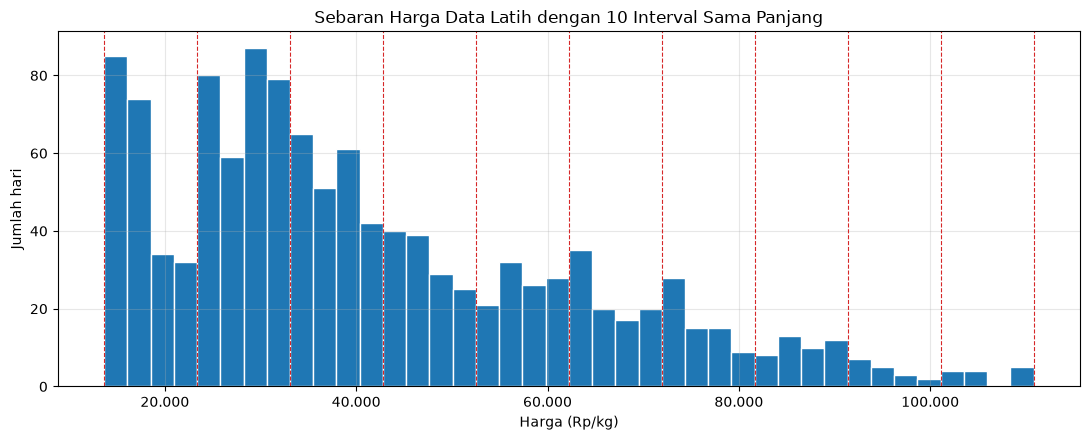

In [11]:
N_INTERVAL = 10
batas = np.linspace(latih.min(), latih.max(), N_INTERVAL + 1)
jumlah, _ = np.histogram(latih, bins=batas)

tabel = pd.DataFrame({
    "batas_bawah": batas[:-1],
    "batas_atas": batas[1:],
    "jumlah_data": jumlah,
    "persen": jumlah / len(latih) * 100,
})
tabel.index = [f"A{i}" for i in range(1, N_INTERVAL + 1)]

print("=" * 62)
print(f"Sebaran data latih pada {N_INTERVAL} interval sama panjang")
print("=" * 62)
print(tabel.round(1).to_string())
print()
print(f"Panjang tiap interval : Rp {batas[1] - batas[0]:,.0f}")
print(f"Interval berisi < 3% data : {', '.join(tabel.index[tabel['persen'] < 3]) or 'tidak ada'}")
print(f"Dua interval terpadat : {', '.join(tabel['persen'].nlargest(2).index)} "
      f"({tabel['persen'].nlargest(2).sum():.1f}% data)")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(latih, bins=40, color="tab:blue", edgecolor="white")
for b in batas:
    ax.axvline(b, color="tab:red", linestyle="--", linewidth=0.8)
ax.set_title(f"Sebaran Harga Data Latih dengan {N_INTERVAL} Interval Sama Panjang")
ax.set_xlabel("Harga (Rp/kg)")
ax.set_ylabel("Jumlah hari")
ax.xaxis.set_major_formatter(rupiah)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(config.DIR_IMG / "3_sebaran_latih_interval_sama_panjang.png", dpi=150)
plt.show()

>INTERPRETASI (Sebaran data latih pada interval sama panjang)
>
>Sebaran harga condong ke kanan: sebagian besar hari berharga rendah dengan ekor panjang ke harga tinggi. Pada sepuluh interval sama panjang (masing-masing Rp 9.715), tiga interval terbawah (A1 sampai A3, Rp 13.650 sampai Rp 42.795) memuat 61,3% data latih, dan dua yang terpadat (A2 dan A1) memuat 43,4%. Sebaliknya, A9 dan A10 hanya berisi 17 dan 13 hari (1,4% dan 1,1%), padahal keduanya menempati seperlima lebar semesta.
>
>Akibatnya, pembagian sama panjang memperlakukan rentang harga yang sering muncul dan yang hampir tidak pernah muncul dengan ukuran interval yang sama. Aturan Fuzzy Time Series pada himpunan A9 dan A10 dipelajari dari belasan data saja sehingga cenderung tidak stabil, sedangkan interval terpadat yang menampung seperempat data tidak dapat dibedakan lebih halus. Hal ini memberi dasar, tetapi bukan bukti, bahwa penentuan batas interval yang mengikuti sebaran data dapat memperbaiki peramalan. Dugaan tersebut diuji pada Notebook 5 dan 6.

### ****6. Implikasi bagi Pemodelan****

#### ****6.1 Mengapa langkah ini penting?****

Eksplorasi hanya berguna bila temuannya diterjemahkan menjadi keputusan perancangan yang tercatat. Bagian ini merangkum apa yang kami temukan dan bagaimana temuan tersebut memengaruhi notebook-notebook berikutnya.

#### ****6.2 Temuan dan keputusan****

1. Semesta pembicaraan dibangun dari data latih (Rp 13.650 sampai Rp 110.800) dengan margin kecil. Seluruh nilai validasi dan uji berada dalam rentang tersebut, sehingga tidak ada nilai yang jatuh di luar semesta.
2. Sebaran harga condong ke kanan, dan interval sama panjang menyia-nyiakan interval pada rentang harga tinggi yang jarang muncul. Ini memberi dasar untuk mengoptimasi batas interval, tetapi manfaatnya baru dianggap terbukti bila lolos uji pada data validasi dan uji.
3. Tingkat harga data uji rata-rata 1,45 kali data latih dan berada pada himpunan fuzzy yang aturannya dipelajari dari data yang sedikit. Kami mengusulkan setelah konfigurasi dipilih lewat data validasi, model akhir dilatih ulang pada gabungan data latih dan validasi sebelum diuji, sesuai dengan sistem nyata yang memakai data terbaru. Hasil tanpa pelatihan ulang tetap dilaporkan sebagai pembanding.
4. Hari Senin sekitar dua kali lebih bergejolak daripada hari lain. Galat peramalan akan dilaporkan per hari, dan aplikasi web akan menandai bahwa prediksi untuk hari Senin kurang pasti.
5. Diduga sejak 2023 hari libur diisi dengan pengulangan harga terakhir. Karena itu data validasi dan uji dapat mengandung hari-hari yang mudah ditebak. Pada Notebook 6, evaluasi juga dilaporkan hanya pada hari ketika harga berubah sebagai uji sensitivitas, sehingga keunggulan model yang mengulang harga lama tidak berlebihan.
6. Harga sangat persisten (autokorelasi 0,991), sehingga model naive diperkirakan sangat sulit dikalahkan. Perubahan harga berkorelasi positif sampai lima pencatatan, tetapi Fuzzy Time Series orde satu tidak memanfaatkannya. Fuzzy Time Series orde dua dicatat sebagai pengembangan opsional bila waktu memungkinkan.

#### ****6.3 Yang belum diputuskan****

Jumlah interval dan parameter Algoritma Genetika belum ditetapkan di sini karena keduanya harus dipilih lewat data validasi. Sebagai usulan awal, rentang jumlah interval yang dicoba adalah 5 sampai 20.

### ****7. Ringkasan dan Langkah Berikutnya****

#### ****7.1 Ringkasan****

1. Dari 1.790 hari pada berkas mentah, 44 hari kosong dihapus tanpa diisi nilai buatan, dan 1 anomali sesaat (21 Agustus 2020) dikeluarkan, sehingga tersisa 1.745 data bersih. Data bersih dan catatan pembersihan tersimpan di folder Dataset/Clean.
2. Data dibagi berurutan menjadi 1.221 hari latih, 261 hari validasi, dan 263 hari uji. Seluruh nilai validasi dan uji berada dalam rentang harga data latih.
3. Hari Senin sekitar dua kali lebih bergejolak daripada hari lain.
4. Diduga sejak 2023 hari libur diisi dengan pengulangan harga terakhir, sehingga 4,2% perubahan pada data latih bernilai nol.
5. Harga sangat persisten (autokorelasi 0,991 pada selisih satu pencatatan), sehingga model naive diperkirakan menjadi pembanding yang sangat kuat.
6. Sebaran harga condong ke kanan, dan dua dari sepuluh interval sama panjang hanya berisi 2,5% data latih. Hal ini menjadi dasar mencoba mengoptimasi batas interval.

#### ****7.2 Langkah berikutnya****

1. Notebook 4 (model dasar): membangun fungsi metrik kesalahan dan model pembanding, yaitu naive, moving average, ARIMA, regresi atau perceptron, serta Fuzzy Time Series interval sama panjang yang ditulis dari nol.
2. Notebook 5 (Algoritma Genetika): mengoptimasi batas interval Fuzzy Time Series.
3. Notebook 6 sampai 8: evaluasi lengkap, persiapan penerapan web, serta analisis hasil dan keterbatasan.